Saving let.webp to let.webp


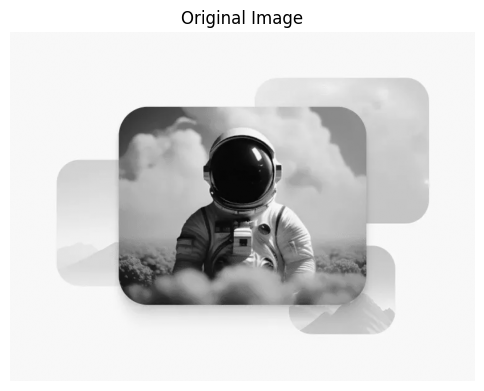

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage.util import random_noise
from google.colab import files
import io

# Upload image
uploaded = files.upload()

# Read uploaded image
image_name = next(iter(uploaded))
img = Image.open(io.BytesIO(uploaded[image_name])).convert('L')
img = np.array(img, dtype=np.float64) / 255.0

plt.figure(figsize=(6, 5))
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis('off')
plt.show()

In [2]:
# Set random seed for reproducibility
np.random.seed(42)

# Image dimensions
rows, cols = img.shape
size = img.shape

# Noise parameters
a, b = 0.0, 1.0       # Uniform limits
mu, sigma = 0.0, 0.08 # Gaussian parameters
k, theta = 2, 0.08    # Erlang shape and scale
lam = 10.0            # Exponential rate
ray_sigma = 0.15      # Rayleigh scale

# 1. Uniform noise: p(z) = 1/(b-a)
uniform_noise = np.random.uniform(a, b, size)
uniform_img = np.clip(img + (uniform_noise - 0.5) * 0.2, 0, 1)

# 2. Gaussian noise: p(z) = 1/(sigma*sqrt(2*pi)) * exp(...)
gaussian_noise = np.random.normal(mu, sigma, size)
gaussian_img = np.clip(img + gaussian_noise, 0, 1)

# 3. Erlang noise: Gamma distribution for integer shape k
# p(z) = lam^k * z^(k-1) * exp(-lam*z) / (k-1)!
erlang_noise = np.random.gamma(shape=k, scale=theta, size=size)
erlang_noise = erlang_noise - np.mean(erlang_noise)
erlang_img = np.clip(img + erlang_noise, 0, 1)

# 4. Exponential noise: p(z) = lam * exp(-lam*z), z >= 0
exponential_noise = np.random.exponential(scale=1/lam, size=size)
exponential_noise = exponential_noise - np.mean(exponential_noise)
exponential_img = np.clip(img + exponential_noise, 0, 1)

# 5. Rayleigh noise: p(z) = (z/b^2)*exp(-z^2/(2*b^2)), z >= 0
rayleigh_noise = np.random.rayleigh(scale=ray_sigma, size=size)
rayleigh_noise = rayleigh_noise - np.mean(rayleigh_noise)
rayleigh_img = np.clip(img + rayleigh_noise, 0, 1)

print("All five noise types generated successfully!")

All five noise types generated successfully!


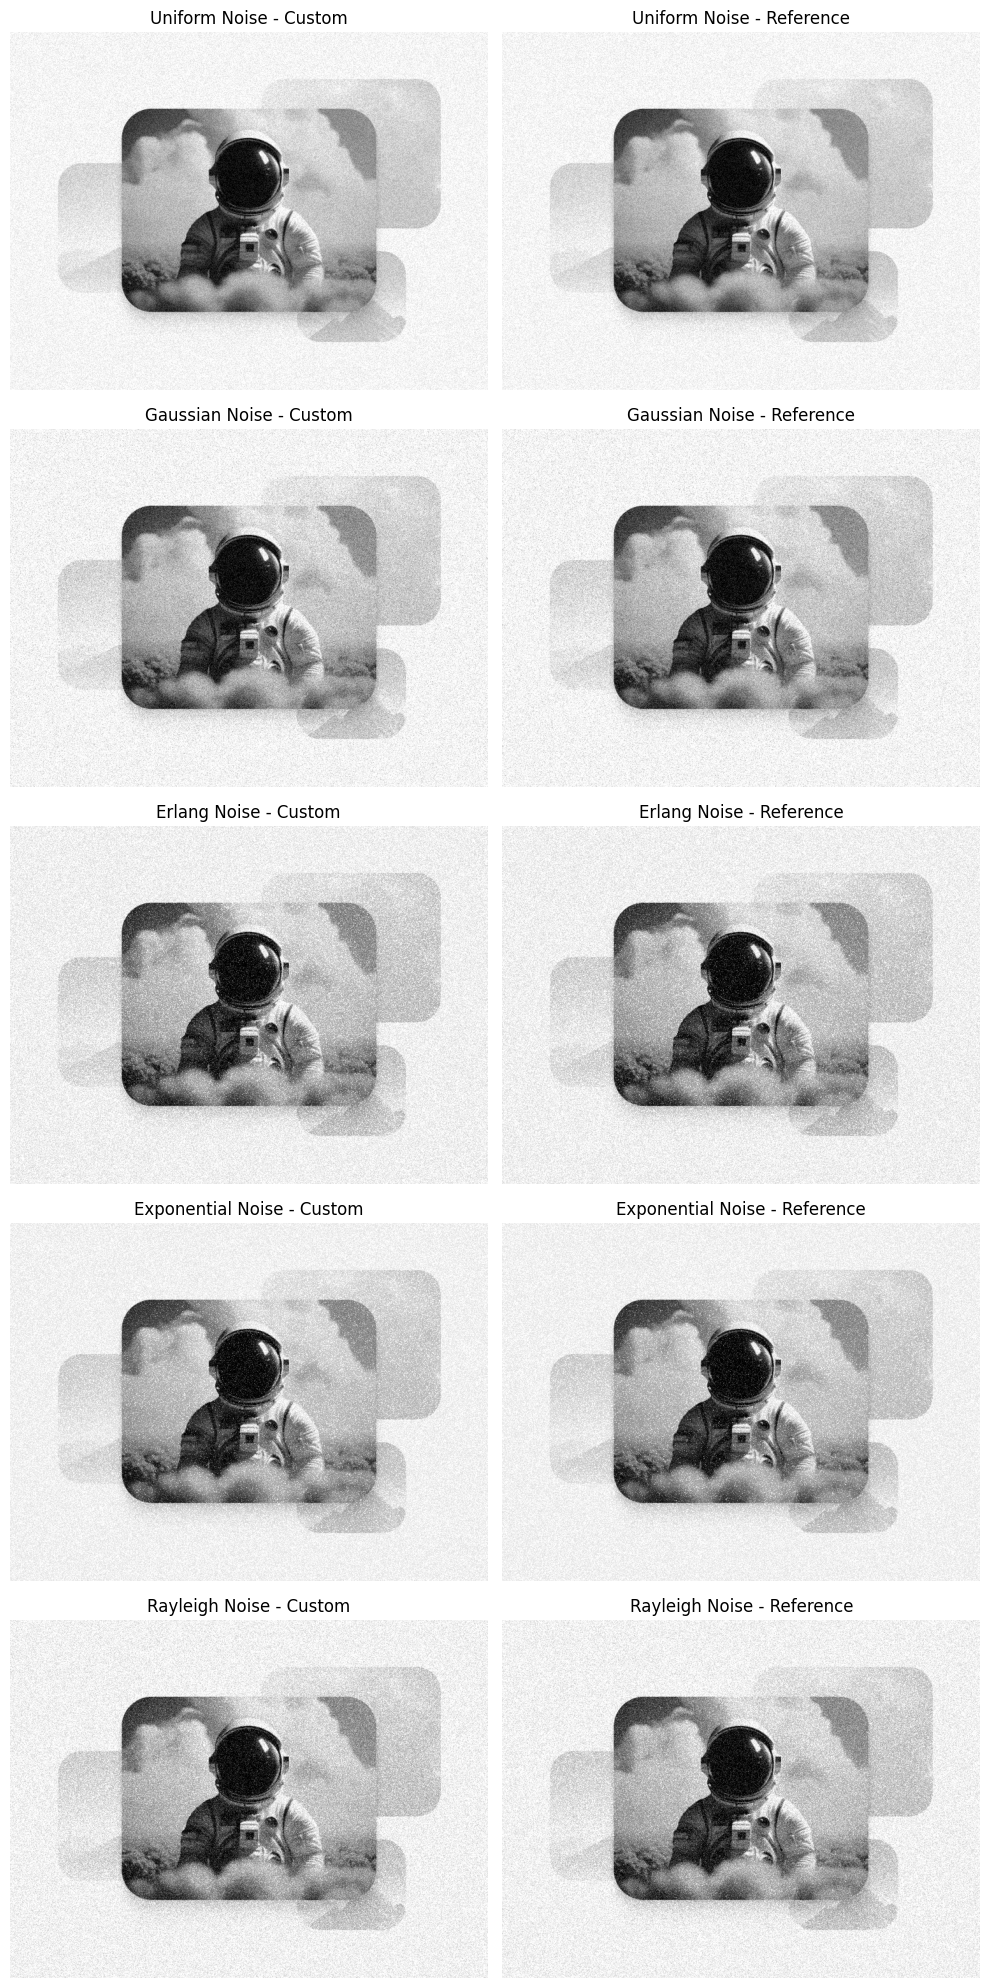

In [5]:
from skimage.util import random_noise
import numpy as np
import matplotlib.pyplot as plt

# Generate noise using inbuilt/reference functions

builtin_images = {
    # Uniform noise: generated manually using NumPy
    "Uniform": np.clip(
        img + np.random.default_rng(42).uniform(-0.1, 0.1, img.shape),
        0, 1
    ),

    # Gaussian noise: inbuilt function
    "Gaussian": np.clip(
    img + np.random.default_rng(42).normal(
        0, sigma, img.shape
    ), 0, 1
),

    # Erlang noise
    "Erlang": np.clip(
        img + (
            np.random.default_rng(42).gamma(k, theta, img.shape)
            - k * theta
        ), 0, 1
    ),

    # Exponential noise
    "Exponential": np.clip(
        img + (
            np.random.default_rng(42).exponential(1/lam, img.shape)
            - 1/lam
        ), 0, 1
    ),

    # Rayleigh noise
    "Rayleigh": np.clip(
        img + (
            np.random.default_rng(42).rayleigh(ray_sigma, img.shape)
            - ray_sigma * np.sqrt(np.pi/2)
        ), 0, 1
    )
}

custom_images = {
    "Uniform": uniform_img,
    "Gaussian": gaussian_img,
    "Erlang": erlang_img,
    "Exponential": exponential_img,
    "Rayleigh": rayleigh_img
}

fig, axes = plt.subplots(5, 2, figsize=(10, 20))

for i, name in enumerate(custom_images):
    axes[i, 0].imshow(custom_images[name], cmap='gray', vmin=0, vmax=1)
    axes[i, 0].set_title(f"{name} Noise - Custom")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(builtin_images[name], cmap='gray', vmin=0, vmax=1)
    axes[i, 1].set_title(f"{name} Noise - Reference")
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

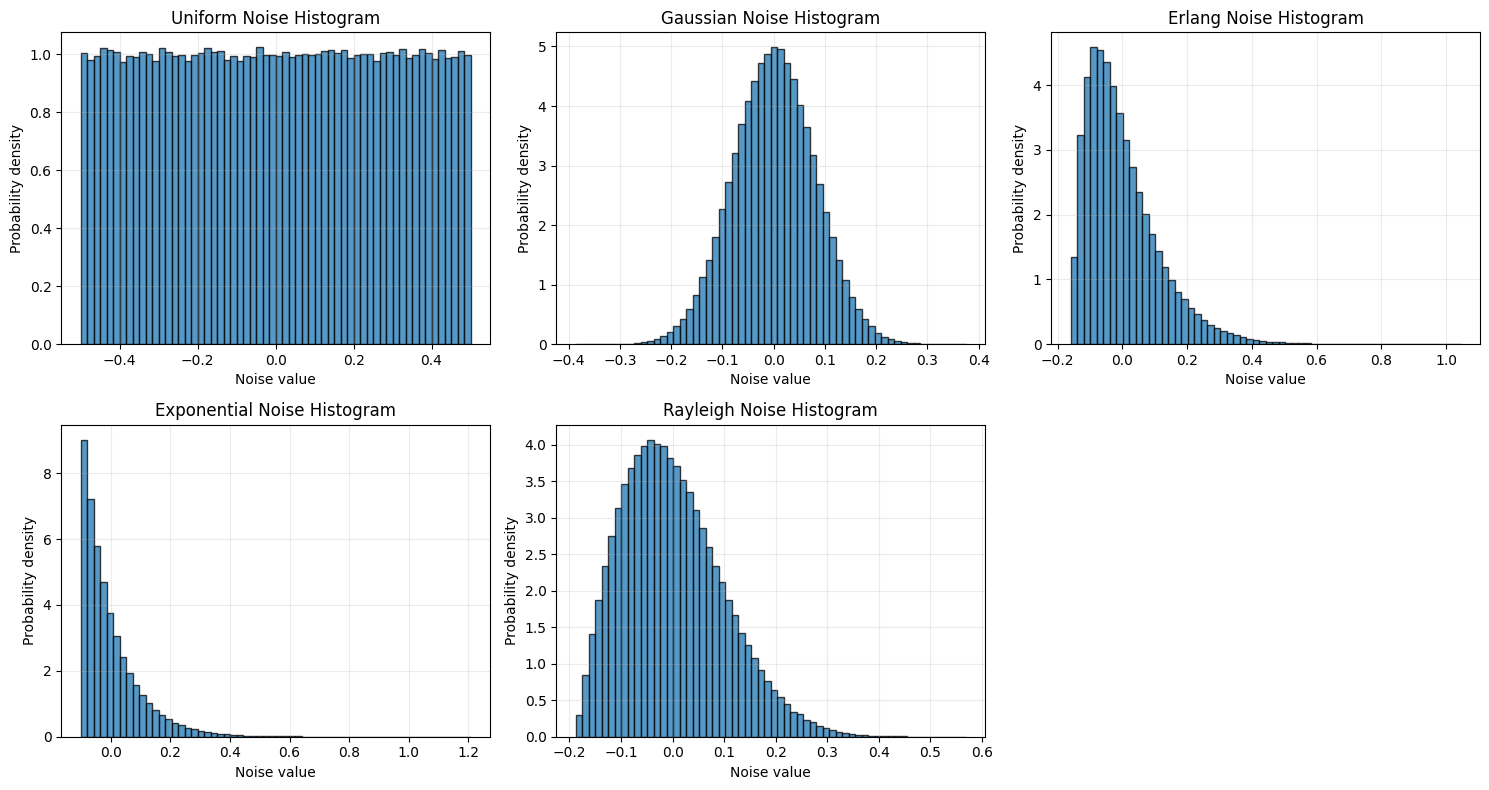

In [6]:
noise_data = {
    "Uniform": uniform_noise - 0.5,
    "Gaussian": gaussian_noise,
    "Erlang": erlang_noise,
    "Exponential": exponential_noise,
    "Rayleigh": rayleigh_noise
}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for i, (name, noise) in enumerate(noise_data.items()):
    axes[i].hist(noise.ravel(), bins=60, density=True,
                 alpha=0.75, edgecolor='black')
    axes[i].set_title(f"{name} Noise Histogram")
    axes[i].set_xlabel("Noise value")
    axes[i].set_ylabel("Probability density")
    axes[i].grid(alpha=0.25)

axes[5].axis('off')
plt.tight_layout()
plt.show()